# Response analysis: electricity price $X$ → follower response $Y$

This notebook analyzes the paired datasets:

- `X_SB.npy` → `Y_SB.npy`
- `X_BG.npy` → `Y_BG.npy`
- `X_IP.npy` → `Y_IP.npy`

Each row is one sample. Both $X_i$ and $Y_i$ are 24-dimensional trajectories:

$$X_i=(\pi_1,\ldots,\pi_{24}), \qquad Y_i=(p_{mg,1},\ldots,p_{mg,24}).$$

The analysis covers data quality, same-hour response curves, cross-hour dependence, representative trajectories, and empirical response lookup for a user-specified price trajectory.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 4)

PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
SCENARIOS = ("SB", "BG", "IP")
HOURS = np.arange(1, 25)


def load_response_data(data_dir=DATA_DIR, scenarios=SCENARIOS):
    """Load and validate all aligned X/Y response datasets."""
    loaded = {}
    for scenario in scenarios:
        x_path = data_dir / f"X_{scenario}.npy"
        y_path = data_dir / f"Y_{scenario}.npy"
        if not x_path.is_file() or not y_path.is_file():
            raise FileNotFoundError(f"Missing {x_path.name} or {y_path.name} in {data_dir}")

        X = np.load(x_path).astype(float)
        Y = np.load(y_path).astype(float)
        if X.ndim != 2 or Y.ndim != 2:
            raise ValueError(f"{scenario}: expected 2-D arrays, got X{X.shape}, Y{Y.shape}")
        if X.shape != Y.shape:
            raise ValueError(f"{scenario}: X{X.shape} and Y{Y.shape} are not aligned")
        if X.shape[1] != 24:
            raise ValueError(f"{scenario}: expected 24 hours, got {X.shape[1]}")
        if not np.isfinite(X).all() or not np.isfinite(Y).all():
            raise ValueError(f"{scenario}: arrays contain NaN or infinite values")
        loaded[scenario] = {"X": X, "Y": Y}
    return loaded


data = load_response_data()
for scenario in SCENARIOS:
    print(f"{scenario}: X{data[scenario]['X'].shape}, Y{data[scenario]['Y'].shape}")

reference_X = data[SCENARIOS[0]]["X"]
print("All scenarios use exactly the same X samples:", all(
    np.array_equal(reference_X, data[s]["X"]) for s in SCENARIOS[1:]
))

SB: X(10000, 24), Y(10000, 24)
BG: X(10000, 24), Y(10000, 24)
IP: X(10000, 24), Y(10000, 24)
All scenarios use exactly the same X samples: True


## 1. Data summary and comparability

`X` was generated independently for every hour from the interval `[0, 1.5]`. Because all scenarios use the same random seed, the three `X` arrays should be exactly identical. This makes the scenario comparison paired and fair.

`Y` is aggregate grid import `p_mg` in MW. Daily totals below are sums over 24 one-hour periods and are therefore reported in MWh.

In [2]:
def same_hour_correlations(X, Y):
    """Return corr(X_t, Y_t) for each hour t."""
    return np.array([np.corrcoef(X[:, t], Y[:, t])[0, 1] for t in range(X.shape[1])])


summary_rows = []
for scenario in SCENARIOS:
    X, Y = data[scenario]["X"], data[scenario]["Y"]
    daily_total = Y.sum(axis=1)
    same_corr = same_hour_correlations(X, Y)
    summary_rows.append({
        "scenario": scenario,
        "samples": len(X),
        "X_min": X.min(),
        "X_max": X.max(),
        "Y_min_MW": Y.min(),
        "Y_max_MW": Y.max(),
        "Y_mean_MW": Y.mean(),
        "Y_std_MW": Y.std(),
        "mean_corr(X_t,Y_t)": same_corr.mean(),
        "daily_total_mean_MWh": daily_total.mean(),
        "daily_total_std_MWh": daily_total.std(),
        "daily_CV_percent": 100 * daily_total.std() / daily_total.mean(),
    })

summary = pd.DataFrame(summary_rows).set_index("scenario")
display(summary)

comparison_rows = []
for i, left in enumerate(SCENARIOS):
    for right in SCENARIOS[i + 1:]:
        Y_left, Y_right = data[left]["Y"], data[right]["Y"]
        comparison_rows.append({
            "pair": f"{left}–{right}",
            "same_X": np.array_equal(data[left]["X"], data[right]["X"]),
            "corr(all Y values)": np.corrcoef(Y_left.ravel(), Y_right.ravel())[0, 1],
            "mean_abs_Y_difference_MW": np.mean(np.abs(Y_left - Y_right)),
            "corr(daily totals)": np.corrcoef(Y_left.sum(1), Y_right.sum(1))[0, 1],
        })

display(pd.DataFrame(comparison_rows).set_index("pair"))

,samples,X_min,X_max,Y_min_MW,Y_max_MW,Y_mean_MW,Y_std_MW,"mean_corr(X_t,Y_t)",daily_total_mean_MWh,daily_total_std_MWh,daily_CV_percent
scenario,,,,,,,,,,,
SB,10000,1.9753e-05,1.5,0.0000e+00,0.9447,0.4877,0.3105,-0.8408,11.7056,1.3097,11.1890
BG,10000,1.9753e-05,1.5,6.8381e-02,0.6928,0.4309,0.1966,-0.8640,10.3409,0.0096,0.0924
IP,10000,1.9753e-05,1.5,-1.7322e-07,10.0000,4.6108,3.7126,-0.7649,110.6588,0.1589,0.1436


,same_X,corr(all Y values),mean_abs_Y_difference_MW,corr(daily totals)
pair,,,,
SB–BG,True,0.4934,0.2277,0.0695
SB–IP,True,0.5837,4.1981,0.0525
BG–IP,True,0.3182,4.3009,0.1630


## 2. Same-hour price-response curves

The plots estimate the marginal relationship $E[Y_t\mid X_t\text{ in price bin}]$ by pooling all sample-hour pairs. Since each hour has the same uniform price distribution, every hour receives approximately equal weight.

These curves answer “when the price in an hour lies in this interval, what is the average grid import in that hour?” They do **not** imply that a scalar price uniquely determines `Y_t` when cross-hour constraints are present.

count  Y_mean_MW  Y_q10_MW  Y_q90_MW
scenario price_left price_right                                      
SB       0.00       0.15         23810     0.6970    0.4899    0.8979
         0.15       0.30         24112     0.6945    0.4899    0.8979
         0.30       0.45         24127     0.6925    0.4899    0.8979
         0.45       0.60         23763     0.6866    0.4835    0.8979
         0.60       0.75         24027     0.6736    0.4833    0.8721
         0.75       0.90         23951     0.6548    0.4537    0.8635
         0.90       1.05         24034     0.5977    0.4146    0.8220
         1.05       1.20         24211     0.1207    0.0000    0.3501
         1.20       1.35         23766     0.0323    0.0000    0.1426
         1.35       1.50         24199     0.0318    0.0000    0.1426
BG       0.00       0.15         23810     0.5118    0.2898    0.6928
         0.15       0.30         24112     0.5118    0.2897    0.6928
         0.30       0.45         24127     0.5102    0.2896    0.6928
         0.45       0.60         23763     0.5051    0.2627    0.6928
         0.60       0.75         24027     0.4769    0.2347    0.6924
         0.75       0.90         23951     0.4237    0.1652    0.6792
         0.90       1.05         24034     0.3704    0.0990    0.6057
         1.05       1.20         24211     0.3408    0.0974    0.5739
         1.20       1.35         23766     0.3300    0.0970    0.5515
         1.35       1.50         24199     0.3292    0.0968    0.5514
IP       0.00       0.15         23810     8.7664    5.6809   10.0000
         0.15       0.30         24112     8.2094    4.3319   10.0000
         0.30       0.45         24127     7.4759    3.4320   10.0000
         0.45       0.60         23763     6.5491    2.3423   10.0000
         0.60       0.75         24027     5.1172    0.9218    9.5592
         0.75       0.90         23951     3.4797    0.0000    6.9110
         0.90       1.05         24034     2.4359    0.0000    6.2953
         1.05       1.20         24211     1.8293    0.0000    5.7063
         1.20       1.35         23766     1.3334    0.0000    4.5508
         1.35       1.50         24199     0.9546    0.0000    3.6153

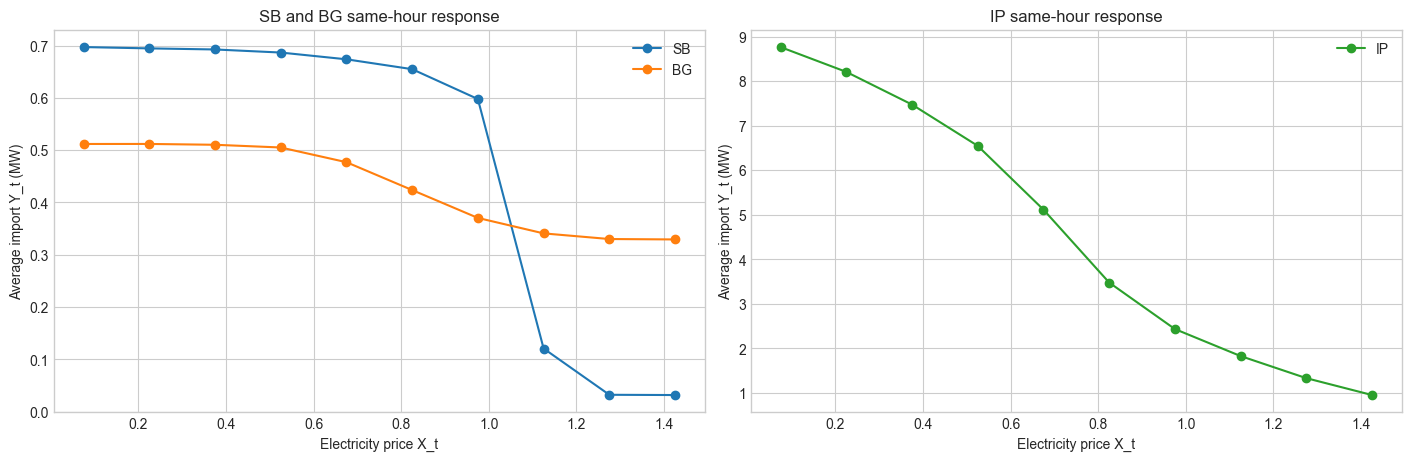

In [3]:
PRICE_EDGES = np.linspace(0.0, 1.5, 11)
PRICE_CENTERS = (PRICE_EDGES[:-1] + PRICE_EDGES[1:]) / 2


def binned_response(X, Y, edges=PRICE_EDGES):
    """Compute pooled same-hour Y statistics for bins of X."""
    x_flat, y_flat = X.ravel(), Y.ravel()
    bin_id = np.clip(np.digitize(x_flat, edges[1:-1]), 0, len(edges) - 2)
    rows = []
    for b in range(len(edges) - 1):
        values = y_flat[bin_id == b]
        rows.append({
            "price_left": edges[b],
            "price_right": edges[b + 1],
            "price_center": (edges[b] + edges[b + 1]) / 2,
            "count": len(values),
            "Y_mean_MW": values.mean(),
            "Y_q10_MW": np.quantile(values, 0.10),
            "Y_q90_MW": np.quantile(values, 0.90),
        })
    return pd.DataFrame(rows)


response_tables = {
    scenario: binned_response(data[scenario]["X"], data[scenario]["Y"])
    for scenario in SCENARIOS
}

display(pd.concat(
    {scenario: table.set_index(["price_left", "price_right"])[["count", "Y_mean_MW", "Y_q10_MW", "Y_q90_MW"]]
     for scenario, table in response_tables.items()},
    names=["scenario"]
))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
for scenario in ("SB", "BG"):
    table = response_tables[scenario]
    axes[0].plot(table["price_center"], table["Y_mean_MW"], marker="o", label=scenario)
axes[0].set(title="SB and BG same-hour response", xlabel="Electricity price X_t", ylabel="Average import Y_t (MW)")
axes[0].legend()

ip_table = response_tables["IP"]
axes[1].plot(ip_table["price_center"], ip_table["Y_mean_MW"], marker="o", color="tab:green", label="IP")
axes[1].set(title="IP same-hour response", xlabel="Electricity price X_t", ylabel="Average import Y_t (MW)")
axes[1].legend()
plt.show()

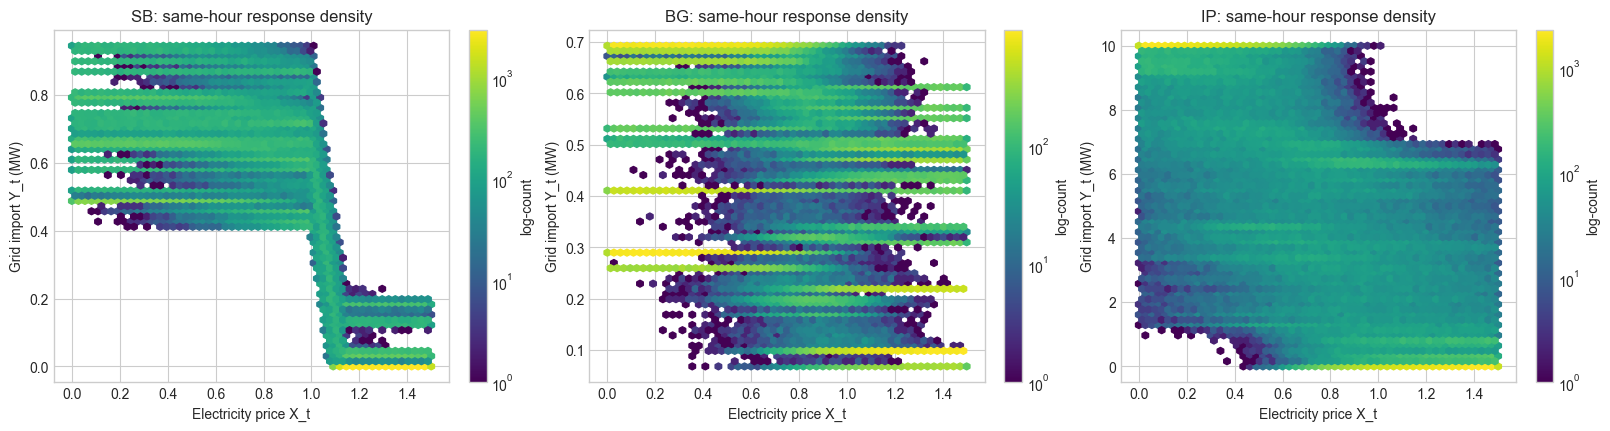

In [4]:
# Density view of all 240,000 (X_t, Y_t) sample-hour pairs in each scenario.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True)
for ax, scenario in zip(axes, SCENARIOS):
    X, Y = data[scenario]["X"], data[scenario]["Y"]
    density = ax.hexbin(X.ravel(), Y.ravel(), gridsize=55, mincnt=1, bins="log", cmap="viridis")
    ax.set(title=f"{scenario}: same-hour response density", xlabel="Electricity price X_t", ylabel="Grid import Y_t (MW)")
    fig.colorbar(density, ax=ax, label="log-count")
plt.show()

## 3. Cross-hour dependence

For each scenario, the following 24×24 matrix contains

$$C_{t,s}=\operatorname{corr}(X_t,Y_s).$$

- A strong negative diagonal means a high price at hour `t` suppresses import at the same hour.
- Off-diagonal structure means that changing one hour's price affects another hour's response, usually through storage, thermal dynamics, ramping, minimum-on-time, or terminal constraints.
- Correlation describes association under the sampled price distribution; it is not a complete nonlinear sensitivity measure.

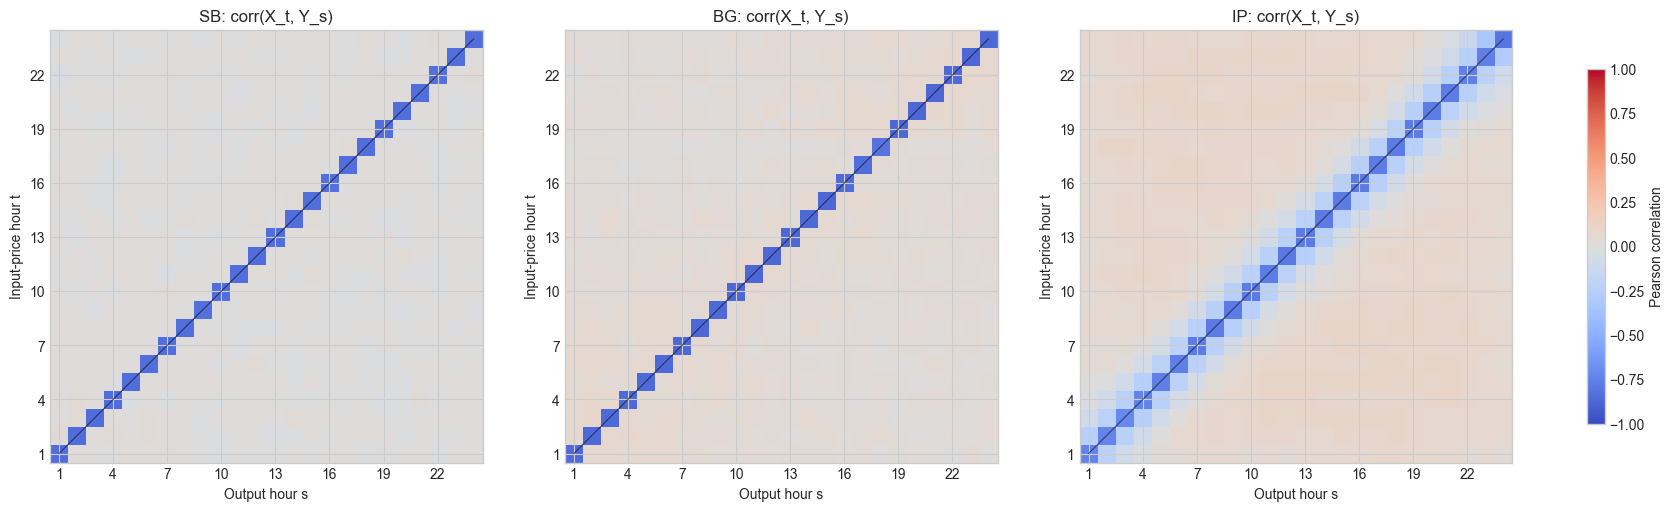

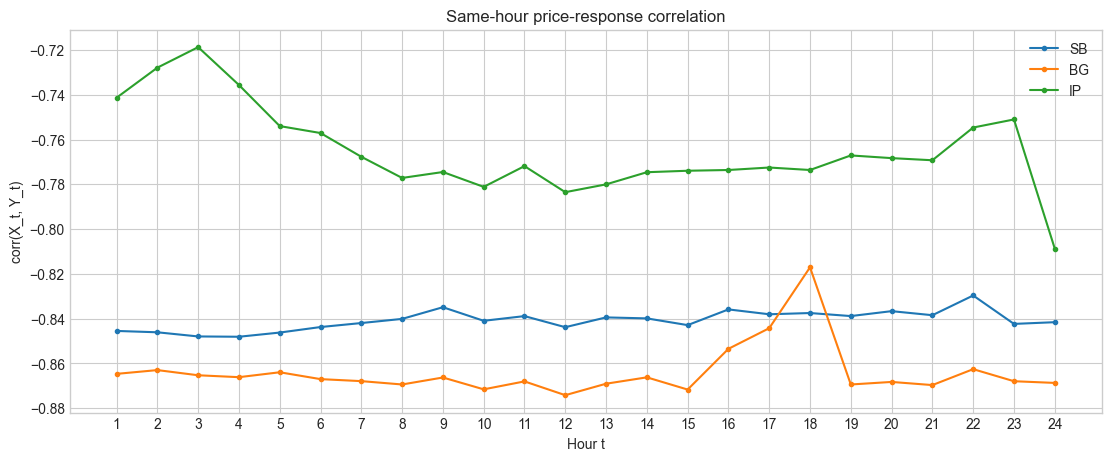

In [5]:
def cross_hour_correlation(X, Y):
    """Matrix with rows X hours and columns Y hours."""
    T = X.shape[1]
    return np.corrcoef(X.T, Y.T)[:T, T:]


correlation_matrices = {
    scenario: cross_hour_correlation(data[scenario]["X"], data[scenario]["Y"])
    for scenario in SCENARIOS
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
for ax, scenario in zip(axes, SCENARIOS):
    matrix = correlation_matrices[scenario]
    image = ax.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm", origin="lower", aspect="equal")
    ax.plot(np.arange(24), np.arange(24), color="black", linewidth=0.8, alpha=0.55)
    ax.set(
        title=f"{scenario}: corr(X_t, Y_s)",
        xlabel="Output hour s",
        ylabel="Input-price hour t",
        xticks=np.arange(0, 24, 3),
        yticks=np.arange(0, 24, 3),
    )
    ax.set_xticklabels(np.arange(1, 25, 3))
    ax.set_yticklabels(np.arange(1, 25, 3))
fig.colorbar(image, ax=axes, shrink=0.82, label="Pearson correlation")
plt.show()

fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
for scenario in SCENARIOS:
    ax.plot(HOURS, np.diag(correlation_matrices[scenario]), marker="o", markersize=3, label=scenario)
ax.set(
    title="Same-hour price-response correlation",
    xlabel="Hour t",
    ylabel="corr(X_t, Y_t)",
    xticks=HOURS,
)
ax.legend()
plt.show()

## 4. Average profiles and representative paired trajectories

The average profile separates the fixed hour-of-day baseline from the price effect. The representative samples below are selected by the 10th, 50th, and 90th percentiles of **daily mean price**. Their complete 24-hour trajectories are shown because BG and IP responses cannot be inferred from daily mean price alone.

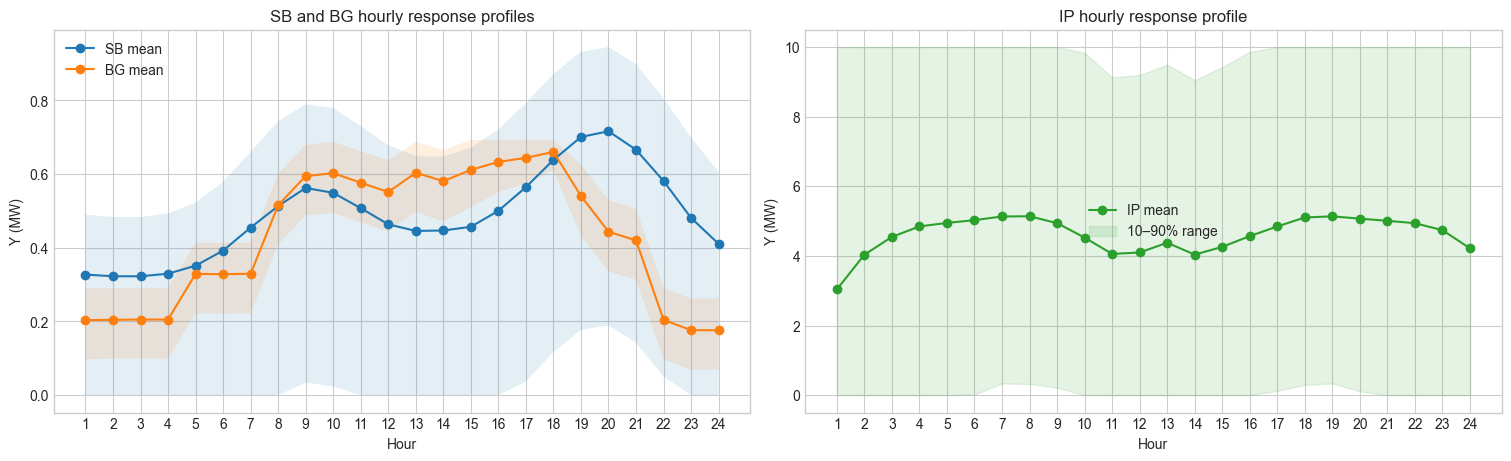

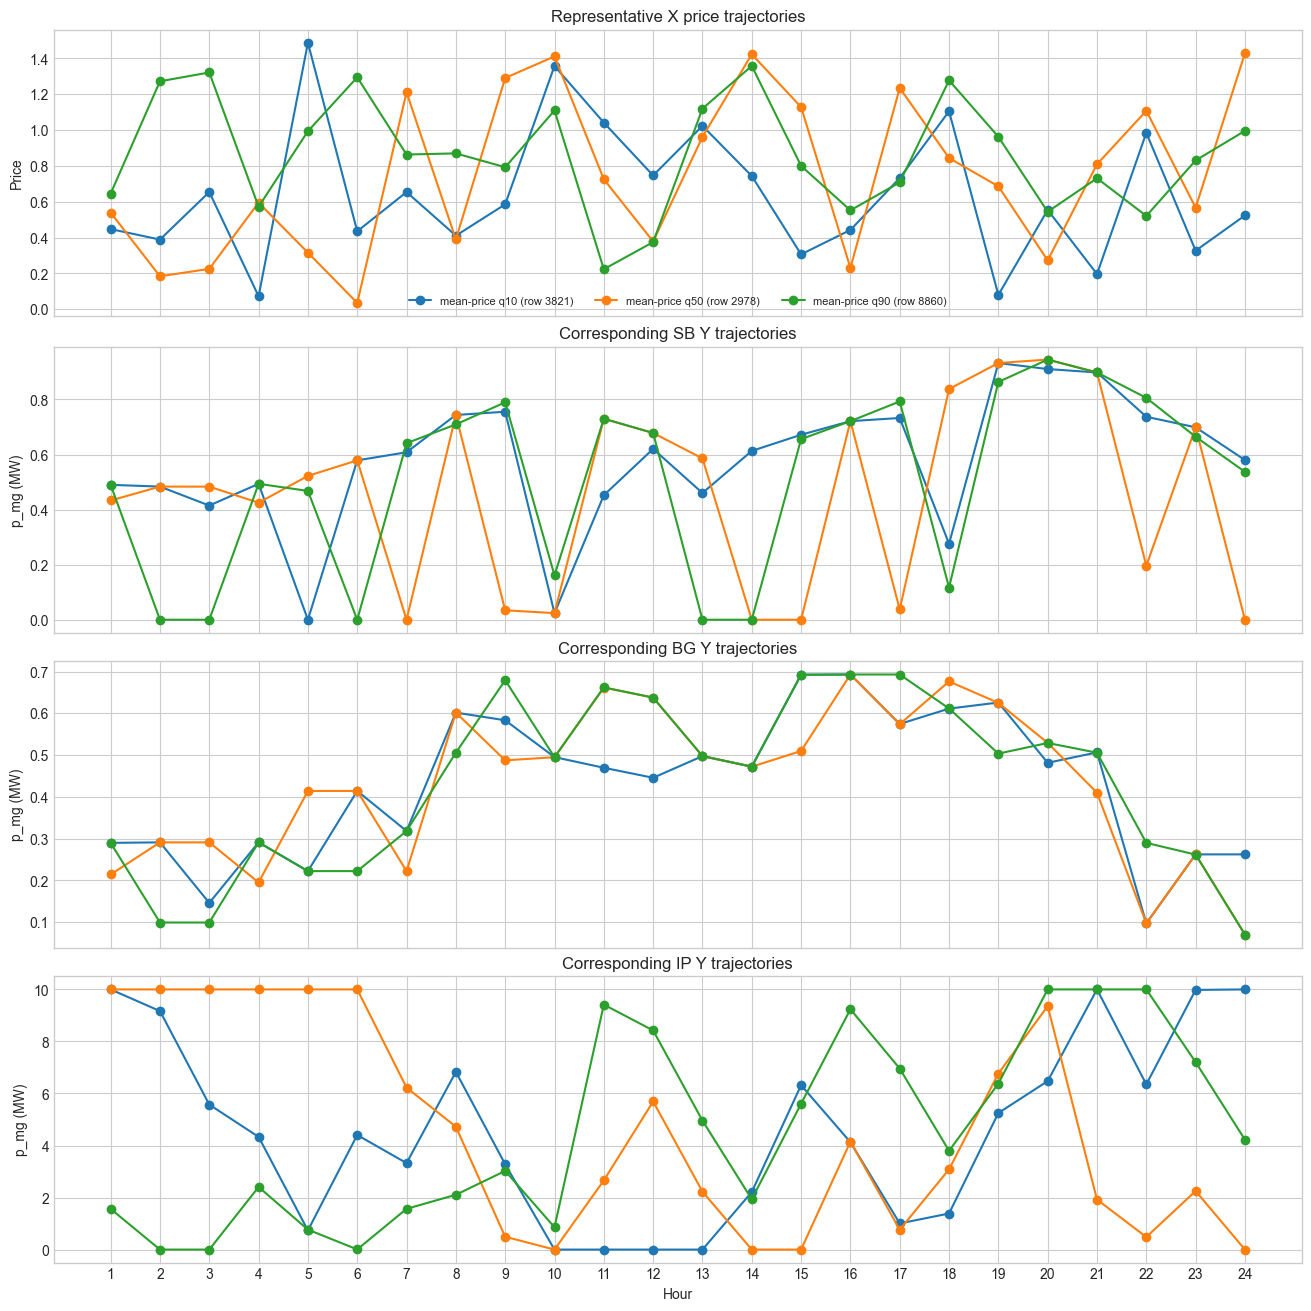

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)
for scenario in ("SB", "BG"):
    Y = data[scenario]["Y"]
    mean = Y.mean(axis=0)
    q10, q90 = np.quantile(Y, [0.10, 0.90], axis=0)
    axes[0].plot(HOURS, mean, marker="o", label=f"{scenario} mean")
    axes[0].fill_between(HOURS, q10, q90, alpha=0.12)
axes[0].set(title="SB and BG hourly response profiles", xlabel="Hour", ylabel="Y (MW)", xticks=HOURS)
axes[0].legend()

Y = data["IP"]["Y"]
mean = Y.mean(axis=0)
q10, q90 = np.quantile(Y, [0.10, 0.90], axis=0)
axes[1].plot(HOURS, mean, marker="o", color="tab:green", label="IP mean")
axes[1].fill_between(HOURS, q10, q90, color="tab:green", alpha=0.12, label="10–90% range")
axes[1].set(title="IP hourly response profile", xlabel="Hour", ylabel="Y (MW)", xticks=HOURS)
axes[1].legend()
plt.show()

# The X samples are identical across scenarios, so one set of indices is used for all Y datasets.
X = reference_X
mean_price = X.mean(axis=1)
quantile_targets = [0.10, 0.50, 0.90]
selected_indices = [int(np.argmin(np.abs(mean_price - np.quantile(mean_price, q)))) for q in quantile_targets]
labels = [f"mean-price q{int(q*100)} (row {idx})" for q, idx in zip(quantile_targets, selected_indices)]

fig, axes = plt.subplots(4, 1, figsize=(13, 13), sharex=True, constrained_layout=True)
for idx, label in zip(selected_indices, labels):
    axes[0].plot(HOURS, X[idx], marker="o", label=label)
axes[0].set(title="Representative X price trajectories", ylabel="Price")
axes[0].legend(ncol=3, fontsize=8)

for ax, scenario in zip(axes[1:], SCENARIOS):
    for idx, label in zip(selected_indices, labels):
        ax.plot(HOURS, data[scenario]["Y"][idx], marker="o", label=label)
    ax.set(title=f"Corresponding {scenario} Y trajectories", ylabel="p_mg (MW)")
axes[-1].set(xlabel="Hour", xticks=HOURS)
plt.show()

## 5. Query an empirical $X\rightarrow Y$ response

`nearest_response` finds the closest observed 24-hour price trajectories and averages their `Y` values. This is useful for inspecting the dataset and answering “have I observed a similar X, and what Y did it produce?”

It is **not** a replacement for the trained L2O surrogate:

- 24-dimensional nearest neighbors can still be far away even with 10,000 samples;
- the reported normalized distance should always be checked;
- for optimization or out-of-sample prediction, use the trained scenario model.

,row,price_RMSE_distance,mean_price,daily_Y_MWh
0,0,0.0000,0.9033,110.6191
1,4828,0.3457,0.8968,110.5624
2,3846,0.3585,0.8510,110.7142
3,5787,0.3652,0.9032,110.8748
4,8662,0.3659,0.8853,110.6196
5,4567,0.3685,0.8157,110.6705
6,3288,0.3686,0.7584,110.8337
7,6893,0.3687,0.8492,110.5193
8,4198,0.3770,0.8520,111.0074
9,3890,0.3916,0.8319,110.8502


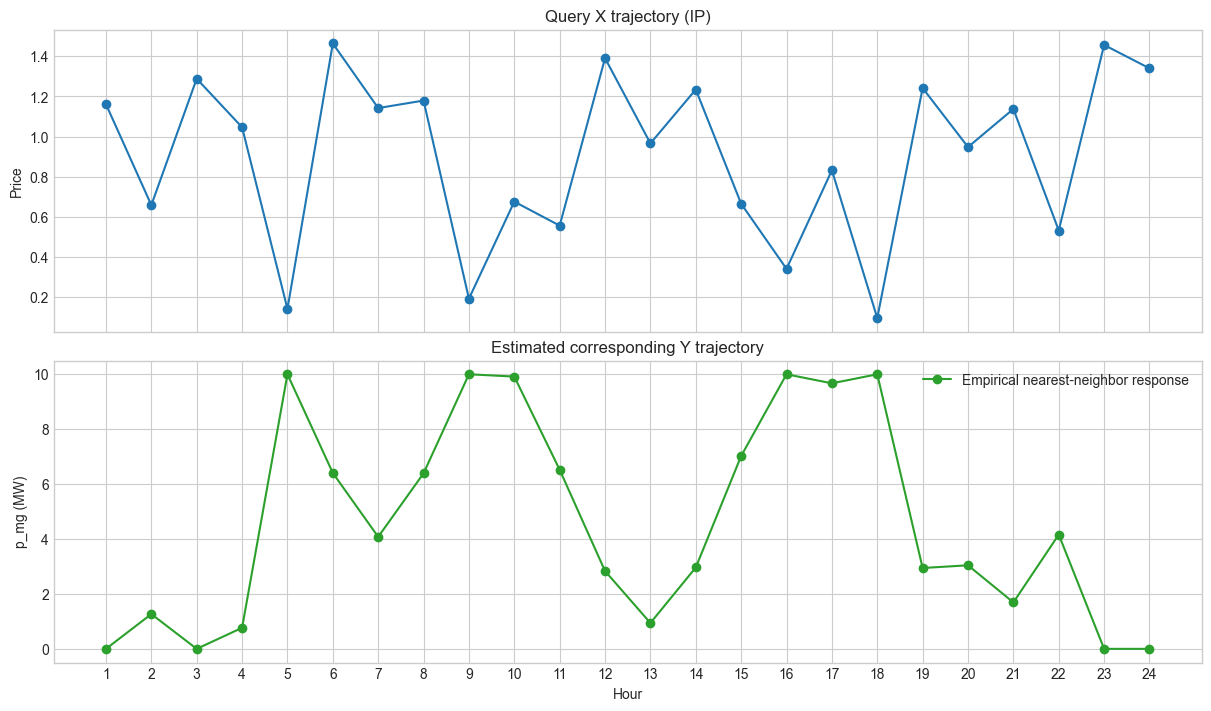

In [7]:
def nearest_response(x_query, scenario, k=20):
    """Return a distance-weighted empirical Y estimate and its nearest observations.

    Distance is RMSE in price units over the 24-hour trajectory.
    """
    scenario = scenario.upper()
    if scenario not in data:
        raise ValueError(f"scenario must be one of {tuple(data)}")

    x_query = np.asarray(x_query, dtype=float).reshape(-1)
    X, Y = data[scenario]["X"], data[scenario]["Y"]
    if x_query.shape != (X.shape[1],):
        raise ValueError(f"Expected x_query shape ({X.shape[1]},), got {x_query.shape}")
    if not np.isfinite(x_query).all():
        raise ValueError("x_query contains NaN or infinite values")
    if not 1 <= k <= len(X):
        raise ValueError(f"k must be between 1 and {len(X)}")

    distances = np.sqrt(np.mean((X - x_query) ** 2, axis=1))
    indices = np.argpartition(distances, k - 1)[:k]
    indices = indices[np.argsort(distances[indices])]

    if distances[indices[0]] < 1e-12:
        estimate = Y[indices[0]].copy()
    else:
        weights = 1.0 / np.maximum(distances[indices], 1e-12)
        weights /= weights.sum()
        estimate = np.average(Y[indices], axis=0, weights=weights)

    neighbors = pd.DataFrame({
        "row": indices,
        "price_RMSE_distance": distances[indices],
        "mean_price": X[indices].mean(axis=1),
        "daily_Y_MWh": Y[indices].sum(axis=1),
    })
    return estimate, neighbors


# Example: modify these two lines to analyze your own trajectory.
scenario_query = "IP"
x_query = reference_X[0].copy()  # Replace with any length-24 price vector.

estimated_y, nearest_rows = nearest_response(x_query, scenario_query, k=20)
display(nearest_rows.head(10))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
axes[0].plot(HOURS, x_query, marker="o")
axes[0].set(title=f"Query X trajectory ({scenario_query})", ylabel="Price")
axes[1].plot(HOURS, estimated_y, marker="o", color="tab:green", label="Empirical nearest-neighbor response")
axes[1].set(title="Estimated corresponding Y trajectory", xlabel="Hour", ylabel="p_mg (MW)", xticks=HOURS)
axes[1].legend()
plt.show()

## 6. Interpretation guide

Expected findings for the current datasets:

- **SB:** the cross-hour correlation matrix is almost diagonal. `Y_t` behaves approximately like an hour-specific threshold function of `X_t`, with a sharp import reduction around the upper-middle part of the sampled price range.
- **BG:** same-hour price remains dominant, but HVAC thermal dynamics and storage introduce modest off-diagonal dependence. Price mainly reschedules demand because daily total energy varies very little.
- **IP:** the full 24-hour price pattern is important. Production requirements, ramping, minimum-on-time constraints, material storage, and electrical storage couple multiple hours. Price strongly changes *when* electricity is imported while daily total energy remains nearly fixed.

Therefore, use scalar response curves for interpretation, but use the complete 24-dimensional `X` trajectory when predicting `Y_BG` or `Y_IP`.